In [164]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [165]:
# Импорт библиотек для классического ML и нейронных сетей
import pandas as pd
import numpy as np
import random

# Импорт sklearn для классических алгоритмов
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from lightgbm import LGBMClassifier
from sklearn.metrics import RocCurveDisplay, confusion_matrix, accuracy_score, f1_score, roc_auc_score

# Импорт TensorFlow/Keras для нейронных сетей
import os 
os.environ["TF_USE_LEGACY_KERAS"] = "1" 
import tensorflow as tf
from tensorflow.keras.utils import set_random_seed, to_categorical
from tensorflow.keras.regularizers import l2 as l2_reg
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.initializers import Constant
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, SimpleRNN, Dense, Dropout, Conv1D, GlobalMaxPooling1D
from tensorflow.config.experimental import list_physical_devices
from tensorflow.keras.layers import LSTM

# Пользовательские модули
from helper import *        # вспомогательные функции
from plots import *         # функции визуализации
from nlp import *          # функции обработки естественного языка

In [166]:
gpus = tf.config.list_logical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"GPU доступен: {len(gpu)} устройств")
else:
    print("GPU не доступен, используется CPU")

GPU не доступен, используется CPU


In [167]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
set_random_seed(SEED)

In [168]:
df = pd.read_csv('IMDB Dataset.csv')

1. Препроцессинг и бейслайн

In [169]:
# Создаем копию данных для предобработки
df_preprocessed = df.copy()

# Очищаем отзывы от HTML мусора
df_preprocessed["review_clean"] = df_preprocessed["review"].apply(strip_html)

# Убираем дубликаты из датасета
df_preprocessed = df_preprocessed.drop_duplicates()

# Преобразуем таргет в числовой формат
df_preprocessed["sentiment"] = df_preprocessed["sentiment"].map({"positive": 1, "negative": 0})

In [170]:
# Разделяем данные на признаки и таргет 
X, y = df_preprocessed["review_clean"], df_preprocessed["sentiment"]

In [171]:
# В качестве baseline берем логрег для сравнений с нейросетями

logreg = LogisticRegression(random_state=SEED, max_iter=1000, solver='liblinear')

In [172]:
# Делаем кросс-валидацию с 5 фолдами, используем stratified чтобы в каждом фолде было одинаковое соотношение классов

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [173]:
TFIDF_vectorizer_preprocessor = Pipeline([
    ('vectorizer', TfidfVectorizer(dtype=np.float32)) # Преобразуем int в float , чтобы бустинг не падал
])

scoring = ['accuracy', 'f1', 'roc_auc']
TFIDF_vectorizer_metrics = evaluate_models_cv([('LogReg', logreg)], X, y, TFIDF_vectorizer_preprocessor, cv, scoring)

TFIDF_vectorizer_metrics 

,accuracy,f1,roc_auc,fit_time
LogReg,0.895083,0.896606,0.960956,3.06124


Препроцессинг перед использованием нейросетей

In [174]:
# Параметры для нейронных сетей
MAX_NUM_WORDS = 15000       # максимальное количество уникальных слов в словаре

# Посмотрел в eda 95 квантиль, чтобы покрыть большинство отзывов, взял 600 
MAX_SEQUENCE_LENGTH = 600 # максимальная длина последовательности токенов

In [175]:
# Разделям данные на признак и таргет
X, y = df_preprocessed["review_clean"], df_preprocessed["sentiment"]

# Делаем сплит 

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,
    stratify=y, 
    random_state=SEED
)

In [176]:
# Ограничмваем словарь и превращаем текст в числа
tokenizer = Tokenizer(num_words=MAX_NUM_WORDS)
tokenizer.fit_on_texts(X_train) # учим словарь только на train

seq_train = tokenizer.texts_to_sequences(X_train)
seq_test = tokenizer.texts_to_sequences(X_test)

# Обрезаем или дополняем векторы слов нулями , чтобы получить прямоугольную матрицу
X_train_pad = pad_sequences(seq_train, maxlen = MAX_SEQUENCE_LENGTH)
X_test_pad = pad_sequences(seq_test, maxlen = MAX_SEQUENCE_LENGTH)

2. RNN (Рекуррентная нейронная сеть)

In [177]:
LEARNING_RATE = 0.001
BATCH_SIZE = 128
RNN_UNITS = 64 
EMBEDDING_DIM = 32

DROPOUT_RATE = 0.5
RECCURENT_DROPOUT_RATE = 0
DROPOUT_LAYER_RATE = 0

REGULARIZATION_RATE = 0.0001


In [178]:
model = Sequential([
    Embedding(input_dim=MAX_NUM_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_SEQUENCE_LENGTH, embeddings_regularizer=l2_reg(REGULARIZATION_RATE)),
    Bidirectional(SimpleRNN(RNN_UNITS, dropout=DROPOUT_RATE, recurrent_dropout=RECCURENT_DROPOUT_RATE, return_sequences=False)),
    Dense(1, activation='sigmoid'),
])

optimizer = Adam(learning_rate=LEARNING_RATE)

In [179]:
model.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=['accuracy', 'AUC'])

In [180]:
early = EarlyStopping(monitor="val_auc", mode="max", patience=2, restore_best_weights=True)

In [181]:
history = model.fit(X_train_pad, y_train, validation_split=0.1, epochs=15, batch_size=BATCH_SIZE, callbacks=[early])

Epoch 1/15
279/279 [==============================] - 33s 114ms/step - loss: 0.6898 - accuracy: 0.5621 - auc: 0.6025 - val_loss: 0.5021 - val_accuracy: 0.7749 - val_auc: 0.8580
Epoch 2/15
279/279 [==============================] - 35s 126ms/step - loss: 0.4681 - accuracy: 0.8002 - auc: 0.8752 - val_loss: 0.3966 - val_accuracy: 0.8523 - val_auc: 0.9151
Epoch 3/15
279/279 [==============================] - 35s 127ms/step - loss: 0.3858 - accuracy: 0.8502 - auc: 0.9241 - val_loss: 0.4119 - val_accuracy: 0.8447 - val_auc: 0.9173
Epoch 4/15
279/279 [==============================] - 35s 127ms/step - loss: 0.3327 - accuracy: 0.8828 - auc: 0.9490 - val_loss: 0.4435 - val_accuracy: 0.8185 - val_auc: 0.9029
Epoch 5/15
279/279 [==============================] - 35s 126ms/step - loss: 0.2982 - accuracy: 0.9024 - auc: 0.9624 - val_loss: 0.4066 - val_accuracy: 0.8571 - val_auc: 0.9289
Epoch 6/15
279/279 [==============================] - 35s 126ms/step - loss: 0.2763 - accuracy: 0.9141 - auc: 0.969

In [182]:
split_at = int(len(X_train_pad) * 0.9)
X_val = X_train_pad[split_at:]
y_val = y_train.iloc[split_at:]

val_probabilities = model.predict(X_val).ravel()

124/124 [==============================] - 1s 9ms/step


Строим roc-auc график на валидационной выборке, так как у нас нет кросс-валидации по фолдам. Ее не используем так как обучение будет слишком долгим

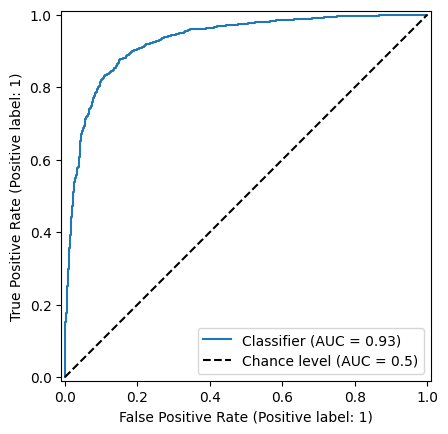

In [183]:
RocCurveDisplay.from_predictions(y_val, val_probabilities, plot_chance_level=True)

In [184]:
val_pred = (val_probabilities >= 0.5).astype(int)

In [185]:
matrix = confusion_matrix(y_val, val_pred)

Text(50.722222222222214, 0.5, 'Настоящий класс')

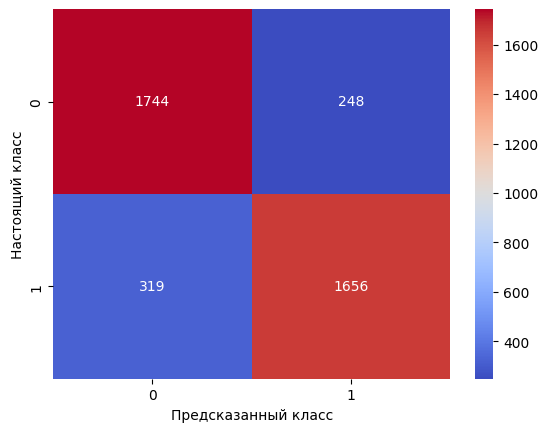

In [186]:
sns.heatmap(data=matrix, annot=True, fmt="d", cmap="coolwarm")

plt.xlabel("Предсказанный класс")
plt.ylabel("Настоящий класс")

Вывод: 

Двунаправленная RNN с обучаемыми эмбеддингами достигла на валидации ROC AUC ≈ 0.94 и accuracy ≈ 0.86. Параметры, перенесённые из примера, на этих данных работали хуже; уменьшение learning_rate до 0.001 и увеличение размерности эмбеддинга до 32 улучшили результат. EarlyStopping вернул веса 6-й эпохи: после неё валидационный AUC снизился. Модель чаще ошибалась, принимая отрицательные отзывы за положительные (418 против 137 обратных ошибок). Это валидационный, не финальный тестовый результат; CV мы не проводили.

3. CNN (Сверточная нейронная сеть)

In [187]:
LEARNING_RATE = 0.001
BATCH_SIZE = 128          
FILTERS = 8               
KERNEL_SIZE = 3           
EMBEDDING_DIM = 32        

REGULARIZATION_STRENGTH = 0.01

In [188]:
model = Sequential([
    Embedding(input_dim=MAX_NUM_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_SEQUENCE_LENGTH, embeddings_regularizer=l2_reg(REGULARIZATION_STRENGTH)),
    Conv1D(filters=FILTERS, kernel_size=KERNEL_SIZE, activation='relu'),
    GlobalMaxPooling1D(),
    Dense(1, activation='sigmoid'),
])

optimizer = Adam(learning_rate=LEARNING_RATE)

In [189]:
model.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=['accuracy', 'AUC'])

In [190]:
early = EarlyStopping(monitor="val_auc", mode="max", patience=2, restore_best_weights=True)

In [191]:
history = model.fit(X_train_pad, y_train, validation_split=0.1, epochs=15, batch_size=BATCH_SIZE, callbacks=[early])

Epoch 1/15
279/279 [==============================] - 2s 7ms/step - loss: 0.8484 - accuracy: 0.6610 - auc: 0.7232 - val_loss: 0.5809 - val_accuracy: 0.7424 - val_auc: 0.8204
Epoch 2/15
279/279 [==============================] - 2s 7ms/step - loss: 0.5433 - accuracy: 0.7748 - auc: 0.8536 - val_loss: 0.5183 - val_accuracy: 0.7935 - val_auc: 0.8732
Epoch 3/15
279/279 [==============================] - 2s 6ms/step - loss: 0.5084 - accuracy: 0.8021 - auc: 0.8819 - val_loss: 0.4962 - val_accuracy: 0.8127 - val_auc: 0.8925
Epoch 4/15
279/279 [==============================] - 2s 7ms/step - loss: 0.4906 - accuracy: 0.8174 - auc: 0.8960 - val_loss: 0.4811 - val_accuracy: 0.8233 - val_auc: 0.9033
Epoch 5/15
279/279 [==============================] - 2s 7ms/step - loss: 0.4780 - accuracy: 0.8258 - auc: 0.9053 - val_loss: 0.4832 - val_accuracy: 0.8210 - val_auc: 0.9042
Epoch 6/15
279/279 [==============================] - 2s 7ms/step - loss: 0.4685 - accuracy: 0.8311 - auc: 0.9110 - val_loss: 0.46

In [192]:
split_at = int(len(X_train_pad) * 0.9)
X_val = X_train_pad[split_at:]
y_val = y_train.iloc[split_at:]

val_probabilities_CNN = model.predict(X_val).ravel()

124/124 [==============================] - 0s 436us/step


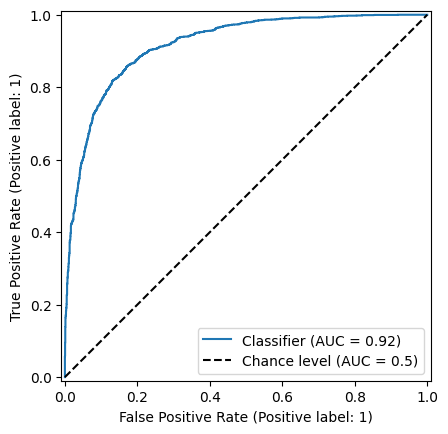

In [193]:
RocCurveDisplay.from_predictions(y_val, val_probabilities_CNN, plot_chance_level=True)

In [194]:
val_pred = (val_probabilities_CNN >= 0.5).astype(int)

In [195]:
matrix = confusion_matrix(y_val, val_pred)

Text(50.722222222222214, 0.5, 'Настоящий класс')

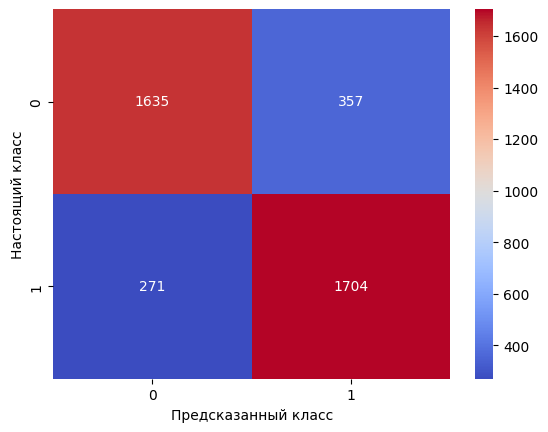

In [196]:
sns.heatmap(data=matrix, annot=True, fmt="d", cmap="coolwarm")

plt.xlabel("Предсказанный класс")
plt.ylabel("Настоящий класс")

Вывод:

CNN имеет метрики чуть ниже, чем у RNN, однако у CNN эпоха обучалась 2 секунды против 36 секунд у RNN, так что CNN дала выигрыш в скорости, но не в качестве.

4. LSTM 

In [197]:
LEARNING_RATE = 0.001
BATCH_SIZE = 128          
LSTM_UNITS = 8               
KERNEL_SIZE = 3           
EMBEDDING_DIM = 32        

DROPOUT_RATE = 0.5
RECCURENT_DROPOUT_RATE = 0
DROPOUT_LAYER_RATE = 0.0

REGULARIZATION_STRENGTH = 0.01

In [198]:
model = Sequential([
    Embedding(input_dim=MAX_NUM_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_SEQUENCE_LENGTH, embeddings_regularizer=l2_reg(REGULARIZATION_STRENGTH)),
    Bidirectional(LSTM(LSTM_UNITS, dropout=DROPOUT_RATE, recurrent_dropout=RECCURENT_DROPOUT_RATE, return_sequences=False)),
    Dense(1, activation='sigmoid')
])

optimizer = Adam(learning_rate=LEARNING_RATE)

In [199]:
model.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=['accuracy', 'AUC'])

In [200]:
early = EarlyStopping(monitor="val_auc", mode="max", patience=2, restore_best_weights=True)

In [201]:
history = model.fit(X_train_pad, y_train, validation_split=0.1, epochs=15, batch_size=BATCH_SIZE, callbacks=[early])

Epoch 1/15
279/279 [==============================] - 21s 69ms/step - loss: 0.8643 - accuracy: 0.6298 - auc: 0.7036 - val_loss: 0.6213 - val_accuracy: 0.7605 - val_auc: 0.8858
Epoch 2/15
279/279 [==============================] - 19s 68ms/step - loss: 0.5818 - accuracy: 0.8086 - auc: 0.8850 - val_loss: 0.5324 - val_accuracy: 0.8540 - val_auc: 0.9280
Epoch 3/15
279/279 [==============================] - 19s 68ms/step - loss: 0.5343 - accuracy: 0.8541 - auc: 0.9280 - val_loss: 0.5228 - val_accuracy: 0.8568 - val_auc: 0.9380
Epoch 4/15
279/279 [==============================] - 19s 68ms/step - loss: 0.5115 - accuracy: 0.8647 - auc: 0.9365 - val_loss: 0.4759 - val_accuracy: 0.8793 - val_auc: 0.9464
Epoch 5/15
279/279 [==============================] - 19s 68ms/step - loss: 0.4986 - accuracy: 0.8683 - auc: 0.9396 - val_loss: 0.4645 - val_accuracy: 0.8795 - val_auc: 0.9460
Epoch 6/15
279/279 [==============================] - 19s 69ms/step - loss: 0.4746 - accuracy: 0.8749 - auc: 0.9438 - va

In [202]:
split_at = int(len(X_train_pad) * 0.9)
X_val = X_train_pad[split_at:]
y_val = y_train.iloc[split_at:]

val_probabilities_LSTM = model.predict(X_val).ravel()

124/124 [==============================] - 2s 9ms/step


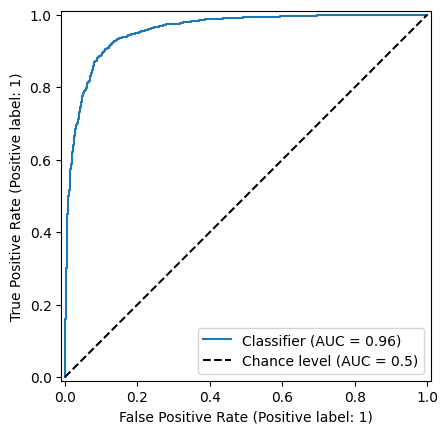

In [203]:
RocCurveDisplay.from_predictions(y_val, val_probabilities_LSTM, plot_chance_level=True)

In [204]:
val_pred = (val_probabilities_LSTM >= 0.5).astype(int)

In [205]:
matrix = confusion_matrix(y_val, val_pred)

Text(50.722222222222214, 0.5, 'Настоящий класс')

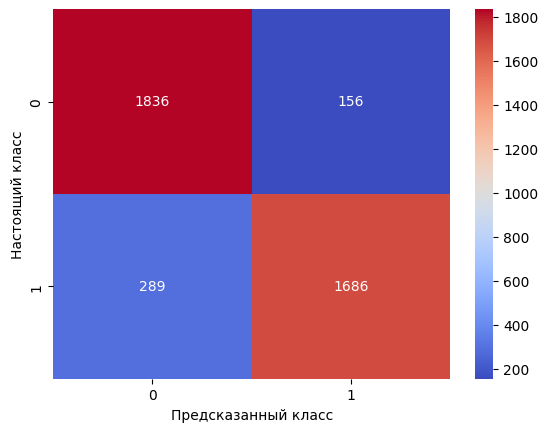

In [206]:
sns.heatmap(data=matrix, annot=True, fmt="d", cmap="coolwarm")

plt.xlabel("Предсказанный класс")
plt.ylabel("Настоящий класс")

5. CNN + Glove

In [207]:
glove_vectors = {}
matrix = np.zeros((MAX_NUM_WORDS, 200), dtype=np.float32)

with open("glove.6B.200d.txt", encoding="utf-8") as file:
    for line in file:
        parts = line.split()
        word = parts[0]

        if word in tokenizer.word_index and tokenizer.word_index[word] < MAX_NUM_WORDS:
            glove_vectors[word] = np.array(parts[1:], dtype=np.float32)


for word, index in tokenizer.word_index.items():
    if index < MAX_NUM_WORDS and word in glove_vectors:
        matrix[index] = glove_vectors[word]





In [208]:
LEARNING_RATE = 0.001
BATCH_SIZE = 128          
FILTERS = 8               
KERNEL_SIZE = 3           
EMBEDDING_DIM = 200      

model = Sequential([
    Embedding(input_dim=MAX_NUM_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_SEQUENCE_LENGTH, 
              weights=[matrix], trainable=False),
    Conv1D(filters=FILTERS, kernel_size=KERNEL_SIZE, activation='relu'),
    GlobalMaxPooling1D(),
    Dense(1, activation='sigmoid'),
])

optimizer = Adam(learning_rate=LEARNING_RATE)

model.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=['accuracy', 'AUC'])

early = EarlyStopping(monitor="val_auc", mode="max", patience=2, restore_best_weights=True)

history = model.fit(X_train_pad, y_train, validation_split=0.1, epochs=15, batch_size=BATCH_SIZE, callbacks=[early])

split_at = int(len(X_train_pad) * 0.9)
X_val = X_train_pad[split_at:]
y_val = y_train.iloc[split_at:]

val_probabilities_CNN_Glove = model.predict(X_val).ravel()


Epoch 1/15
279/279 [==============================] - 7s 25ms/step - loss: 0.5105 - accuracy: 0.7438 - auc: 0.8304 - val_loss: 0.3969 - val_accuracy: 0.8183 - val_auc: 0.9060
Epoch 2/15
279/279 [==============================] - 7s 25ms/step - loss: 0.3710 - accuracy: 0.8356 - auc: 0.9165 - val_loss: 0.3624 - val_accuracy: 0.8404 - val_auc: 0.9230
Epoch 3/15
279/279 [==============================] - 7s 25ms/step - loss: 0.3411 - accuracy: 0.8530 - auc: 0.9294 - val_loss: 0.3420 - val_accuracy: 0.8533 - val_auc: 0.9298
Epoch 4/15
279/279 [==============================] - 7s 25ms/step - loss: 0.3251 - accuracy: 0.8601 - auc: 0.9358 - val_loss: 0.3578 - val_accuracy: 0.8440 - val_auc: 0.9317
Epoch 5/15
279/279 [==============================] - 7s 25ms/step - loss: 0.3128 - accuracy: 0.8674 - auc: 0.9406 - val_loss: 0.3293 - val_accuracy: 0.8533 - val_auc: 0.9344
Epoch 6/15
279/279 [==============================] - 7s 25ms/step - loss: 0.3038 - accuracy: 0.8715 - auc: 0.9441 - val_loss

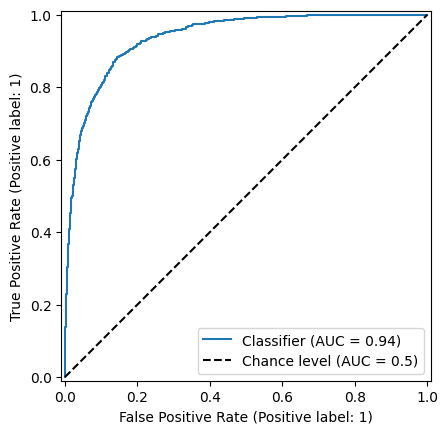

In [209]:
RocCurveDisplay.from_predictions(y_val, val_probabilities_CNN_Glove, plot_chance_level=True)

val_pred = (val_probabilities_CNN_Glove >= 0.5).astype(int)

matrix_conf = confusion_matrix(y_val, val_pred)




Text(50.722222222222214, 0.5, 'Настоящий класс')

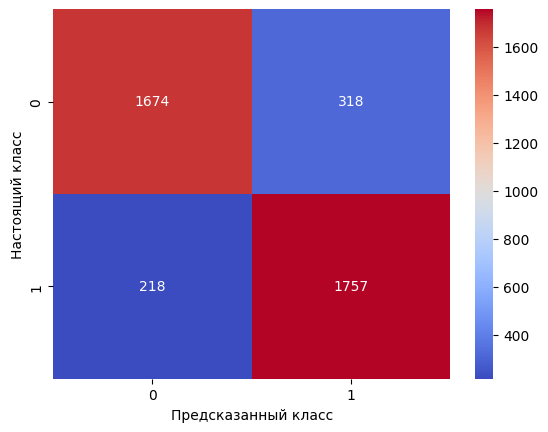

In [210]:
sns.heatmap(data=matrix_conf, annot=True, fmt="d", cmap="coolwarm")

plt.xlabel("Предсказанный класс")
plt.ylabel("Настоящий класс")

In [211]:
results = {}

model_dict = {
    "RNN": val_probabilities,
    "CNN": val_probabilities_CNN,
    "LSTM": val_probabilities_LSTM,
    "CNN_Glove": val_probabilities_CNN_Glove
}

for name, probs in model_dict.items():
    pred = (probs >= 0.5).astype(int)

    results[name] = {
        "accuracy": accuracy_score(y_val, pred),
        "f1": f1_score(y_val, pred),
        "roc_auc": roc_auc_score(y_val, probs),
    }



In [212]:
metrics_df = pd.DataFrame(results).T
metrics_df.loc["TF-IDF + LogReg (CV)", ["accuracy", "f1", "roc_auc"]] = (
    TFIDF_vectorizer_metrics.loc["LogReg", ["accuracy", "f1", "roc_auc"]])
display(metrics_df)

,accuracy,f1,roc_auc
RNN,0.857071,0.853828,0.929015
CNN,0.841694,0.844400,0.918158
LSTM,0.887825,0.883416,0.957170
CNN_Glove,0.864885,0.867654,0.938369
TF-IDF + LogReg (CV),0.895083,0.896606,0.960956


<Axes: >

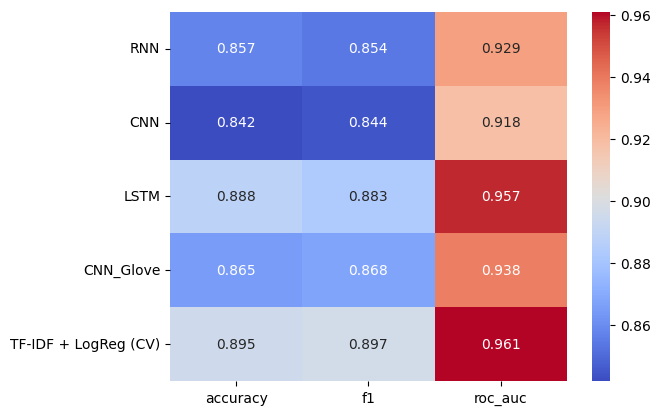

In [213]:
sns.heatmap(data=metrics_df, annot=True, fmt=".3f", cmap="coolwarm")

Вывод:

Среди нейросетей лучший результат у LSTM: ROC-AUC 0.957 , accuracy 0.888. 

TF-IDF + LogisticRegression получила ROC-AUC 0.961 , но это результат на кросс-валидации, а результаты нейросетей получены на одной валидационной выборке с целью экономии времени. Поэтому назвать победителя по этой таблице можно только с оговоркой. 